# Modelo DSATUR de reforestación — notebook principal

Abre **DSATUR/** como carpeta de trabajo, instala `python -m pip install -r requirements.txt` y ejecuta las celdas en orden. Este notebook es la interfaz: los módulos separan cálculos, sin modificar el enfoque independiente de `Algoritmo Genético/`.

La primera celda selecciona un polígono o `"todos"`. El detalle didáctico corresponde al primero; al elegir todos se guardan **P1–P30 y resultados/modelo_completo/**. La configuración inicial usa 12 escenarios por polígono; usa 1 en `ESCENARIOS_LOTE` para una comprobación rápida. Las corridas completas pueden tardar varios minutos.

**Comparación principal:** distribución aleatoria frente al procedimiento completo **DSATUR + búsqueda local**. DSATUR solo se conserva como inicialización y métrica técnica. Reducir J no demuestra mayor supervivencia.

**Economía:** se verifica 12,500 u.m./ha antes de optimizar. Con cuotas fijas, el costo no depende de las posiciones ni del algoritmo; se informan los polígonos inviables respecto al presupuesto, sin cambiar sus cuotas. `estado=ok` significa ejecución espacial validada, no cumplimiento económico: ese indicador se informa por separado.

Las coordenadas son simuladas en metros locales, no georreferenciadas. La matriz C es provisional; se mantiene intacta. La incertidumbre de compras, la calibración ecológica y las cuotas flexibles no se implementan en la optimización actual.


In [1]:
# OPCIONES PRINCIPALES — editar aquí antes de ejecutar todo.
POLIGONOS = "todos"              # entero de 1 a 30 (p. ej. 25), o "todos"
ESCENARIOS_MC = 12         # Monte Carlo del polígono detallado; usar 2 para probar rápido
ESCENARIOS_LOTE = 12       # escenarios por polígono al elegir "todos"; cambiar a 1 para prueba rápida
EJECUTAR_COMPARACION_PRESUPUESTOS = False

from pathlib import Path
from dataclasses import replace, asdict
from time import perf_counter
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code
from reforestacion.config import Config, perfil
from reforestacion.datos import Datos, cargar_competencia
from reforestacion.geometria import dimensiones, flujos, simular_existentes, candidatas, construir_grafo
from reforestacion.algoritmos import objetivo, base_aleatoria, dsatur, busqueda_local
from reforestacion.validacion import validar_solucion
from reforestacion.experimento import ejecutar_lote, guardar_ejecucion, agregar, seleccionar_poligonos, guardar_monte_carlo_por_poligono
from reforestacion import visualizacion as vis
from reforestacion.economia import presupuestos, diagnostico_flexibilidad
from reforestacion.reportes import guardar_modelo_completo, guardar_configuracion

ROOT = Path.cwd()
RESULTADOS = ROOT/'resultados'
RESULTADOS.mkdir(parents=True, exist_ok=True)
poligonos_ids = seleccionar_poligonos(POLIGONOS)
p = poligonos_ids[0]
OUT = RESULTADOS/f'P{p}'
FIGURAS = OUT/'graficas'
FIGURAS.mkdir(parents=True, exist_ok=True)  # detalle paso a paso y figuras del primer polígono elegido
cfg = perfil('completo', poligonos=tuple(poligonos_ids), escenarios=ESCENARIOS_MC)
cfg_lote = replace(cfg, escenarios=ESCENARIOS_LOTE)  # valida también este presupuesto
print('Polígonos seleccionados:', poligonos_ids)
print(f'Detalle y Monte Carlo: P{p}; escenarios MC: {ESCENARIOS_MC}')
if len(poligonos_ids) > 1:
    print(f'Lote seleccionado: {len(poligonos_ids)} polígonos, {ESCENARIOS_LOTE} escenario(s) por polígono.')
plt.rcParams.update({'font.size':10,'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def mostrar(fig, nombre):
    fig.savefig(FIGURAS/(nombre+'.png'),dpi=140,bbox_inches='tight')
    plt.show()
    plt.close(fig)
display(pd.Series(asdict(cfg),name='Configuración'))

Polígonos seleccionados: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
Detalle y Monte Carlo: P1; escenarios MC: 12
Lote seleccionado: 30 polígonos, 12 escenario(s) por polígono.


presupuesto_por_ha                                                   12500.0
densidad                                                               658.0
aspecto                                                                  1.0
paso_malla                                                               3.4
separacion_min                                                           3.4
radio                                                                    6.0
semilla                                                             20261014
escenarios                                                                12
intentos_local                                                          6000
max_propuestas_posicion                                               200000
presupuesto                                                             fijo
intentos_por_nueva                                                        10
poligonos                  (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...

## 2. Datos proporcionados por el socio formador
`data/especies.csv`: especie, género, meta por ha y costo unitario. `data/inventario.csv`: área y conteos por especie en 30 polígonos. `data/supervivencia_porcentajes.csv`: contexto histórico, **sin uso como predicción ni como C**. `data/fuentes_sha256.json` registra huellas de documentos originales; no contiene esos documentos y no se usa para regenerar datos.

Los nombres Opuntia engelmannii y Opuntia streptacantha ya están normalizados en CSV. La moneda no está especificada: u.m. P13=5.05 ha es una interpretación editorial pendiente; las etiquetas del mapa no son necesariamente los IDs tabulados. El cargador rechaza duplicados, conteos no enteros, especies ausentes y áreas inconsistentes.

In [2]:
datos = Datos(ROOT)
S = datos.S
area, existentes, cuotas, nuevas = datos.poligono(p,cfg)
tabla = datos.especies.copy()
tabla['existentes'] = existentes
tabla['cuota_final'] = cuotas
tabla['nuevas'] = nuevas
tabla['costo_nuevas_um'] = nuevas * tabla.costo_unitario
display(tabla)
print(f'P{p}: {area} ha; {existentes.sum()} existentes + {nuevas.sum()} nuevas = {cuotas.sum()}')
print(f'30 polígonos: {datos.areas.sum():.2f} ha; adquisición P{p}: {tabla.costo_nuevas_um.sum():.2f} u.m.')
presupuesto_30 = presupuestos(datos,cfg)
print('Diagnóstico económico de los 30 (cuotas fijas; no se modifican):')
display(presupuesto_30[['poligono','presupuesto_um','costo_um','saldo_um',
                      'presupuesto_utilizado_pct','cumple_presupuesto']].round(3))
incumplen = presupuesto_30.loc[~presupuesto_30.cumple_presupuesto,'poligono'].tolist()
print('Incumplen individualmente:',incumplen)
print('Saldo agregado (no compensa automáticamente déficits individuales):',presupuesto_30.saldo_um.sum())


P1: 1.28 ha; 165 existentes + 677 nuevas = 842
30 polígonos: 183.01 ha; adquisición P1: 15903.50 u.m.
Diagnóstico económico de los 30 (cuotas fijas; no se modifican):
Incumplen individualmente: [5, 9, 10, 12, 18, 23]
Saldo agregado (no compensa automáticamente déficits individuales): 8017.000000000007


,especie,genero,objetivo_por_ha,costo_unitario,existentes,cuota_final,nuevas,costo_nuevas_um
0,Agave lechuguilla,Agave,42,26.0,8,54,46,1196.0
1,Agave salmiana,Agave,196,26.0,46,251,205,5330.0
2,Agave scabra,Agave,42,26.0,16,54,38,988.0
3,Agave striata,Agave,42,26.0,16,54,38,988.0
4,Opuntia cantabrigiensis,Opuntia,49,18.0,11,63,52,936.0
5,Opuntia engelmannii,Opuntia,38,21.0,14,48,34,714.0
6,Opuntia robusta,Opuntia,73,18.0,18,93,75,1350.0
7,Opuntia streptacantha,Opuntia,64,18.0,12,82,70,1260.0
8,Prosopis laevigata,Prosopis,86,26.5,15,110,95,2517.5
9,Yucca filifera,Yucca,26,26.0,9,33,24,624.0


,poligono,presupuesto_um,costo_um,saldo_um,presupuesto_utilizado_pct,cumple_presupuesto
0,1,16000.0,15903.5,96.5,99.397,True
1,2,83000.0,82574.5,425.5,99.487,True
2,3,84500.0,84474.0,26.0,99.969,True
3,4,17250.0,17056.0,194.0,98.875,True
4,5,100000.0,100563.0,-563.0,100.563,False
5,6,97750.0,96869.0,881.0,99.099,True
6,7,69125.0,68803.5,321.5,99.535,True
7,8,70500.0,69456.0,1044.0,98.519,True
8,9,88875.0,88983.0,-108.0,100.122,False
9,10,76375.0,76877.5,-502.5,100.658,False


## 3. Conjuntos e índices
Los nodos se identifican por `(polígono, índice local)`; las coordenadas son pares reales $(x,y)$ en metros. El índice local es solo una etiqueta, no una celda binaria de ocupación.

|Símbolo|Significado|Tipo en Python|Unidad|Origen|Equivalente|
|---|---|---|---|---|---|
|$P$|30 polígonos tabulados|lista de int|—|socio|`datos.areas.index`|
|$S$|10 especies|lista de str|—|socio|`datos.S`|
|$F_p$|sitios existentes|array `(nf,2)`|m|simulación, conteos reales|`F`|
|$V_p$|sitios nuevos seleccionados|array `(nv,2)`|m|selección geométrica|`V`|
|$U_p=F_p\cup V_p$|todos los sitios|array `(N,2)`|m|concatenación|`g['U']`|
|$E_p$|pares no dirigidos cercanos|array `(M,2)` de int|—|distancias|`g['pares']`|

En P1 los primeros 165 índices son fijos; los siguientes 677 admiten asignación. Las especies fijas se conocen; **sus coordenadas todavía se simulan**.

In [3]:
display(pd.DataFrame({'conjunto':['P','S',f'F{p}',f'V{p}',f'U{p}'],
    'cardinalidad':[len(datos.areas),len(S),int(existentes.sum()),int(nuevas.sum()),int(cuotas.sum())]}))

,conjunto,cardinalidad
0,P,30
1,S,10
2,F1,165
3,V1,677
4,U1,842


## 4. Parámetros y supuestos
|Símbolo|Significado|Tipo|Unidad|Origen|Python|
|---|---|---|---|---|---|
|$A_p$|área|float|ha|socio|`area`|
|$D$|densidad final objetivo|float|plantas/ha|referencia socio|`cfg.densidad`|
|$T_p$|meta redondeada|int|plantas|regla computacional|`cuotas.sum()`|
|$n_{ps}$|inventario|array int|plantas|socio|`existentes`|
|$R_{ps}$|cuota final|array int|plantas|metas y restos mayores|`cuotas`|
|$q_{ps}=R_{ps}-n_{ps}$|adquisición fija|array int|plantas|derivación|`nuevas`|
|$d_{pij}$|distancia euclidiana|float|m|coordenadas simuladas|`norm(U[i]-U[j])`|
|$d_{min}$|separación ocupada|float|m|supuesto experimental|`cfg.separacion_min`|
|$r$|radio de interacción|float|m|supuesto experimental|`cfg.radio`|
|$C_{st}$|coeficiente competencia|array float|adimensional|supuesto provisional|`C`|
|$w_{pij}$|peso por distancia|array float|adimensional|supuesto|`g['pesos']`|
|$a_{pis}$|especie existente fija|implícita en int|0/1|inventario y permutación|`fijas`|

$T_p=\lfloor A_pD+0.5\rfloor$. Distribuimos $T_p$ según proporciones de las metas por ha: piso y restos mayores, con empates resueltos por orden del catálogo. Si una cuota queda por debajo del inventario, se informa error; no se eliminan plantas.

**P1:** $1.28(658)=842.24$, redondeado a 842. Con 165 existentes hay 677 nuevas. Ni $q$ ni $R$ son decisiones en esta versión. Se usa $d_{min}=3.4$ m y $r=6$ m: funciones distintas.

### Presupuesto y costo conocidos
$$B_p=12500A_p,\qquad C_p=\sum_s c_sq_{ps},\qquad h_p=B_p-C_p,\qquad u_p=100C_p/B_p.$$

|Símbolo|Significado|Tipo|Unidad|Origen|Python|
|---|---|---|---|---|---|
|$c_s$|costo unitario|float|u.m./planta|socio, diapositiva 18|`datos.especies.costo_unitario`|
|$B_p$|presupuesto disponible|float|u.m.|12500 u.m./ha × área|`presupuesto_um`|
|$C_p$|adquisición|float|u.m.|cuotas fijas e inventario|`costo_um`|
|$h_p$|saldo, negativo = déficit|float|u.m.|diferencia|`saldo_um`|
|$u_p$|porcentaje utilizado|float|%|cálculo|`presupuesto_utilizado_pct`|

P1 dispone de 16000 u.m. y requiere 15903.5: saldo 96.5. La moneda no está especificada. Solo se incluyen plantas; faltan transporte, mantenimiento y riego.


In [4]:
print('Cuotas:', cuotas.tolist())
print('Compras:', nuevas.tolist())
if p == 1:
    assert (existentes.sum(), nuevas.sum(), cuotas.sum()) == (165,677,842)
else:
    assert np.all(cuotas >= existentes) and cuotas.sum() == existentes.sum() + nuevas.sum()

Cuotas: [54, 251, 54, 54, 63, 48, 93, 82, 110, 33]
Compras: [46, 205, 38, 38, 52, 34, 75, 70, 95, 24]


## 5. Variables de decisión
Para $i\in V_p$:
$$x_{pis}=\begin{cases}1&\text{especie }s\text{ en sitio nuevo }i,\\0&\text{otro caso.}\end{cases}$$
Se define $y_{pis}=a_{pis}$ en $F_p$ y $y_{pis}=x_{pis}$ en $V_p$.

El código almacena una etiqueta entera por planta (`y[i]`), equivalente a una fila one-hot, para ahorrar memoria. Es una representación de **especie asignada**, no un vector de ocupación del terreno. Las coordenadas permanecen en `g['U']`. Por ejemplo, la etiqueta 2 significa la tercera especie del catálogo.

|Símbolo|Significado|Tipo|Unidad|Origen|Python|
|---|---|---|---|---|---|
|$x_{pis}$|Asignación de especie nueva|binario implícito|0/1|decisión heurística|`y[i] == s`, $i\in V_p$|
|$y_{pis}$|Asignación completa|binario implícito|0/1|fija en F, decisión en V|`y[i] == s`|


In [5]:
ejemplo_etiqueta = 2
print('Especie:', S[ejemplo_etiqueta])
print('Fila binaria equivalente:', np.eye(len(S),dtype=int)[ejemplo_etiqueta])

Especie: Agave scabra
Fila binaria equivalente: [0 0 1 0 0 0 0 0 0 0]


## 6. Función objetivo
$$\min J=\sum_{p\in P}\sum_{\{i,j\}\in E_p}w_{pij}\sum_{s\in S}\sum_{t\in S} C_{st}y_{pis}y_{pjt},\qquad
w_{pij}=\max(0,1-d_{pij}/r).$$
Cada par no dirigido aparece **una sola vez**. Como cada sitio tiene una especie, el producto one-hot selecciona $C_{s_i,s_j}$. En código: `sum(pesos * C[y[i], y[j]])`.

$J=J_{FF}+J_{FV}+J_{VV}$; $J_{FF}$ es constante al optimizar un escenario. Dos plantas a 4 m con $r=6$ tienen peso $1/3$; si son de la misma especie y $C_{ss}=3$, su contribución es 1. Esto es un índice, **no una probabilidad de supervivencia**.

In [6]:
display(Code(inspect.getsource(objetivo),language='python'))
print('Ejemplo de una arista:', (1-4/cfg.radio)*3)

Ejemplo de una arista: 1.0


def objetivo(etiquetas,g,C,desglose=False):
    if len(etiquetas)!=len(g['U']) or np.any((etiquetas<0)|(etiquetas>=len(C))):
        raise ValueError('La función objetivo requiere una asignación completa.')
    i,j=g['pares'].T
    valores=g['pesos']*C[etiquetas[i],etiquetas[j]]
    if not desglose:
        return float(valores.sum())
    ff=(i<g['nf'])&(j<g['nf'])
    vv=(i>=g['nf'])&(j>=g['nf'])
    return {'FF':float(valores[ff].sum()),'FV':float(valores[~(ff|vv)].sum()),
            'VV':float(valores[vv].sum()),'total':float(valores.sum())}

## 7. Restricciones
Para cada polígono y especie:
$$\sum_{s\in S}x_{pis}=1\quad(i\in V_p),\qquad
n_{ps}+\sum_{i\in V_p}x_{pis}=R_{ps},$$
$$\sum_s R_{ps}=T_p=|F_p|+|V_p|,\quad y_{pis}=a_{pis}\ (i\in F_p),\quad x_{pis}\in\{0,1\}.$$
Además, $d_{pij}\ge d_{min}$ para todo par ocupado distinto y todos los sitios pertenecen al rectángulo simulado.

**Separación de etapas:** la geometría selecciona exactamente $|V_p|=\sum_s q_{ps}$ sitios compatibles. Después la heurística solo asigna especies; no decide ocupación ni mueve plantas. Permutar etiquetas nuevas conserva las cuotas. Ningún algoritmo garantiza óptimo global o local certificado.

Se corrige la desigualdad $\le1$ del texto antiguo: aquí todos los sitios de $V_p$ deben ocuparse, por lo que corresponde igualdad.

### Factibilidad económica con cuotas fijas
El requisito adicional deseado es $C_p\le B_p$ **para cada polígono**. Como $q$ ya está fijado, ningún intercambio de especies puede reducir C. Si falla, el modelo con cuotas actuales **y presupuesto obligatorio es inviable**, aunque la asignación espacial sea válida. Se mantienen esos experimentos para diagnóstico y se marca `cumple_presupuesto=False`; no se presentan como soluciones que cumplan presupuesto.

La presentación del socio formador (diapositivas 13 y 15) permite variaciones de hasta ±10% por especie manteniendo el total. La interpretación diagnóstica usada es:
$$\max(n_{ps},\lceil0.9R_{ps}\rceil)\le R'_{ps}\le\lfloor1.1R_{ps}\rfloor,\quad \sum_sR'_{ps}=T_p,\quad q'_{ps}=R'_{ps}-n_{ps}.$$
Minimizar $\sum_sc_sq'_{ps}$ en esa banda es un problema económico auxiliar: partir de límites inferiores y completar por costo creciente da el mínimo (cada intercambio hacia una especie más barata reduce costo). Se conserva densidad total, integralidad e inventario. **No altera R ni q del experimento**. La referencia de la banda sobre R redondeada y los requisitos ecológicos deben confirmarse con el socio.

Si ese mínimo supera B, ni siquiera esa flexibilidad basta. Si es menor, solo demuestra posibilidad aritmética: no certifica equivalencia ecológica. Un modelo futuro debe decidir R' y asignaciones conjuntamente o reparar cuotas antes de DSATUR, imponer B, justificar límites ecológicos y revalidar la heurística. Ni el precio ni J provisional demuestran supervivencia.


In [7]:
assert np.all(cuotas >= existentes)
assert nuevas.sum() + existentes.sum() == cuotas.sum()
print('Cuotas no negativas y meta conciliada; validaciones espaciales después de construir sitios.')
flexibilidad_10 = diagnostico_flexibilidad(datos,cfg)
display(flexibilidad_10.loc[flexibilidad_10.poligono.isin(incumplen),
    ['poligono','costo_fijo_um','presupuesto_um','costo_minimo_banda_10_um',
     'presupuesto_alcanzable_en_banda','aplicado_al_modelo']])


Cuotas no negativas y meta conciliada; validaciones espaciales después de construir sitios.


,poligono,costo_fijo_um,presupuesto_um,costo_minimo_banda_10_um,presupuesto_alcanzable_en_banda,aplicado_al_modelo
4,5,100563.0,100000.0,99195.0,True,False
8,9,88983.0,88875.0,87777.5,True,False
9,10,76877.5,76375.0,75840.5,True,False
11,12,61620.0,61500.0,60789.0,True,False
17,18,68055.5,67500.0,67140.5,True,False
22,23,96603.0,95875.0,95289.0,True,False


## 8. Construcción geométrica de posiciones
El rectángulo tiene superficie $10^4A_p$ m²; aspecto 1 por defecto. Muestreamos posiciones existentes con rechazo por separación y permutamos las especies conservando los conteos. Un límite de propuestas impide ciclos sin fin: agotarlo no prueba imposibilidad matemática.

**Figura 1:** cada símbolo representa una especie en las posiciones simuladas existentes. No son coordenadas observadas. Después generamos una malla triangular de paso 3.4 m, descartamos sitios cercanos a existentes y elegimos por dispersión la cantidad requerida de posiciones nuevas (677 en P1). Este criterio no utiliza C ni especies. Una malla insuficiente produce un fallo registrado, sin relajar distancias.

La densidad ideal de una malla triangular a 3.4 m es diferente de 658 plantas/ha: solo ocupamos parte de la malla. La selección y DSATUR pueden crecer aproximadamente de forma cuadrática; no se guardan matrices completas de distancias.

### Qué es aleatorio y qué es determinista

|Etapa|Comportamiento|Qué permanece fijo|
|---|---|---|
|Inventarios y cuotas|Deterministas, provienen de datos y regla de redondeo|n, R, q y costo|
|Existentes|Propuestas uniformes en el rectángulo; rechazo si violan separación|Conteos y distancia mínima|
|Especies existentes en escenario|Permutación aleatoria de etiquetas de conteos conocidos|Inventario exacto por especie|
|Candidatas|Malla triangular determinista, filtrada usando F simulado|Paso y regla geométrica|
|Sitios nuevos|Elección sucesiva del más alejado de los sitios ocupados|Cantidad exacta de nuevos|
|DSATUR|Determinista dado grafo, C y cuotas; desempates fijos|Posiciones y existentes|
|Referencia y mejora local|Permutación e intercambios con flujos aleatorios separados|Cuotas y geometría del escenario|

Las posiciones nuevas **no son puntos uniformes independientes**. Se determinan a partir de una malla y de las existentes simuladas; por eso varían entre escenarios aunque su selector sea determinista. El rechazo también hace dependientes las posiciones existentes. Durante la optimización, las plantas existentes quedan inmutables; que cambien entre escenarios no significa que el algoritmo las mueva en una solución.

Las coordenadas (0,0) son un origen local artificial. Cada polígono tiene su propio rectángulo; no conocemos orientación, ubicación real ni un sistema de referencia geográfico común. No se deben unir en un mapa global ficticio.


731 candidatas admisibles; 677 seleccionadas; 842 sitios ocupados.


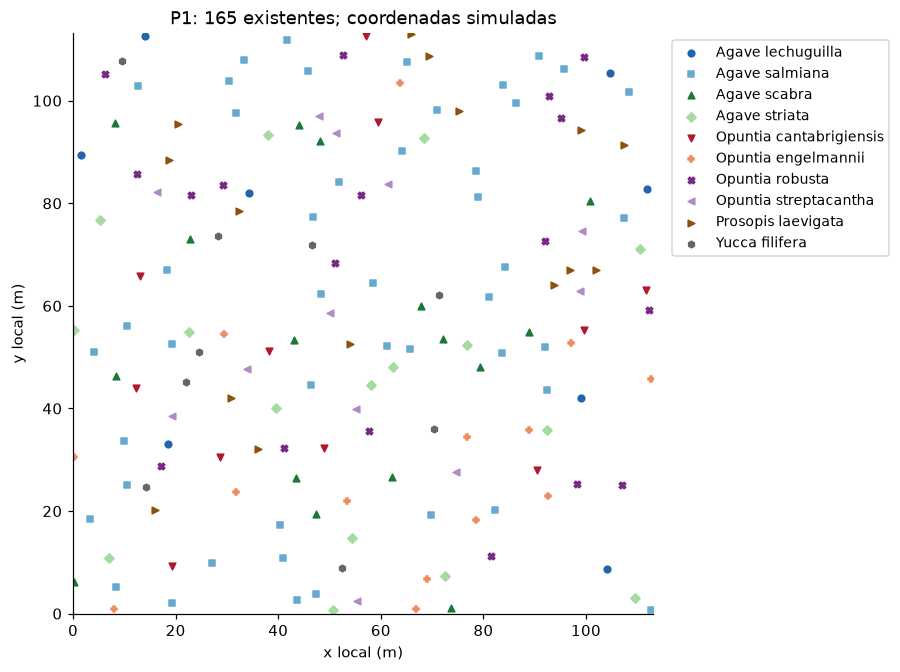

In [8]:
limites = dimensiones(area,cfg)
rng_pos, rng_base, rng_local = flujos(p,0,cfg)
F,fijas = simular_existentes(existentes,limites,cfg,rng_pos)
mostrar(vis.mapa(F,fijas,S,limites,f'P{p}: {len(F)} existentes; coordenadas simuladas'),'01_existentes')
pool,V = candidatas(F,limites,int(nuevas.sum()),cfg)
print(f'{len(pool)} candidatas admisibles; {len(V)} seleccionadas; {len(F)+len(V)} sitios ocupados.')

**Interpretación:** se conservan las etiquetas existentes y se selecciona exactamente el número requerido de sitios nuevos (165 existentes y 677 nuevos en el ejemplo P1). Los espacios vacíos no son decisiones binarias del optimizador de especies.

## 9. Grafo espacial y matriz intercambiable
Conectamos sitios separados a lo más 6 m y guardamos un peso por arista. No hay interacciones entre polígonos.

`config/competencia.json` contiene el orden de especies y una matriz explícita: 3 en la diagonal, 2 entre especies distintas del mismo género y 1 entre géneros diferentes. El cargador valida dimensión, simetría, finitud, no negatividad y orden del catálogo. **Son supuestos**, no mediciones ecológicas.

Más adelante se podría construir C con consumos normalizados de agua y nutrientes, pesos justificados y calibración con datos de campo. Bastaría reemplazar el JSON conservando las propiedades requeridas; no habría que modificar DSATUR ni los deltas.

In [9]:
C = cargar_competencia(ROOT/'config/competencia.json',S)
g = construir_grafo(p,F,V,cfg)
display(pd.DataFrame(C,index=S,columns=S))
print(f"Nodos: {len(g['U'])}; aristas: {len(g['pares'])}")

Nodos: 842; aristas: 3082


,Agave lechuguilla,Agave salmiana,Agave scabra,Agave striata,Opuntia cantabrigiensis,Opuntia engelmannii,Opuntia robusta,Opuntia streptacantha,Prosopis laevigata,Yucca filifera
Agave lechuguilla,3.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave salmiana,2.0,3.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave scabra,2.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0
Agave striata,2.0,2.0,2.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0
Opuntia cantabrigiensis,1.0,1.0,1.0,1.0,3.0,2.0,2.0,2.0,1.0,1.0
Opuntia engelmannii,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,1.0
Opuntia robusta,1.0,1.0,1.0,1.0,2.0,2.0,3.0,2.0,1.0,1.0
Opuntia streptacantha,1.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0,1.0,1.0
Prosopis laevigata,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0
Yucca filifera,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0


## 10. Referencia aleatoria y DSATUR adaptado
La referencia permuta el multiconjunto de especies nuevas: es factible y usa idénticos sitios y cuotas. DSATUR elige el siguiente vértice por saturación (número de especies distintas entre vecinos asignados), luego grado ponderado y menor índice.

Para cada especie disponible calcula $\Delta_i(s)=\sum_{j\in N(i),j\ asignado}w_{ij}C_{s,s_j}$; escoge menor costo incremental, mayor cuota pendiente y menor índice de especie, en ese orden. **No es coloreo propio:** repetir especies se permite con penalización. Como todas las especies pueden ocupar cualquier sitio nuevo y las cuotas suman vacantes, siempre hay especie disponible.

La implementación extraída se muestra para poder relacionar saturación, costos y cuotas con el código. Los desempates y el orden de aristas se conservan del prototipo.

In [10]:
display(Code(inspect.getsource(dsatur),language='python'))
t0=perf_counter();y_base=base_aleatoria(fijas,nuevas,rng_base);t_base=perf_counter()-t0
t0=perf_counter();y_dsatur=dsatur(fijas,nuevas,g,C);t_dsatur=perf_counter()-t0
print(f'Aleatoria: {objetivo(y_base,g,C):.3f}; DSATUR: {objetivo(y_dsatur,g,C):.3f}')

Aleatoria: 1089.007; DSATUR: 991.748


def dsatur(fijas,q,g,C):
    validar_C(C)
    nf,N=len(fijas),len(g['U'])
    if len(q)!=len(C) or np.any(q<0) or np.any(q%1) or int(q.sum())!=N-nf:
        raise ValueError('Cuotas inválidas o incompatibles con el número de posiciones.')
    y=np.full(N,-1,dtype=int)
    y[:nf]=fijas
    restante=q.astype(int).copy()
    vistos=np.zeros((N,len(C)),dtype=bool)
    coste=np.zeros((N,len(C)))
    grado=np.array([sum(w for _,w in ad) for ad in g['ady']])
    def actualizar(i,s):
        for j,w in g['ady'][i]:
            if y[j]<0:
                vistos[j,s]=True
                coste[j]+=w*C[:,s]
    for i,s in enumerate(fijas):
        actualizar(i,int(s))
    for _ in range(N-nf):
        libres=np.flatnonzero(y<0)
        saturacion=vistos[libres].sum(axis=1)
        i=int(libres[np.lexsort((libres,-grado[libres],-saturacion))[0]])
        factibles=np.flatnonzero(restante>0)
        if not len(factibles):
            raise ValueError('No queda especie factible.')
        s=int(min(factibles,key=lambda s:(coste[i,s],-restante[s],s)))
        y[i]=s
        restante[s]-=1
        actualizar(i,s)
    assert not restante.any()
    return y

## 11. DSATUR + búsqueda local
1. Proponer dos sitios **nuevos distintos** uniformemente al azar.
2. Si tienen la misma especie, contar y descartar la propuesta.
3. Evaluar $\Delta J$ sumando aristas incidentes. La arista entre ambos sitios no cambia porque C es simétrica.
4. Intercambiar solo si hay mejora negativa. Se conserva la tolerancia histórica: $\Delta J<-10^{-10}$, para descartar empates de coma flotante.

Nunca se modifican plantas existentes. Cuotas y coordenadas quedan fijas. El presupuesto cuenta propuestas, incluidas las descartadas; terminarlo no certifica óptimo local.

El diagnóstico opcional de trayectoria tiene **propuestas en X y J en Y**. Descensos = mejoras aceptadas; mesetas = sin mejora aceptada. Incluye la meseta hasta la última propuesta. Se muestran contadores que satisfacen propuestas = iguales + evaluados y evaluados = aceptados + rechazados.

In [11]:
display(Code(inspect.getsource(busqueda_local),language='python'))
y_final,historia,stats = busqueda_local(y_dsatur,g,C,rng_local,cfg.intentos(len(V)))
display(pd.Series(stats,name='Búsqueda local'))
detalle = dict(g=g,F=F,V=V,fijas=fijas,limites=limites,historia=historia)
if cfg.diagnosticos:
    for nombre,fig in vis.diagnosticos(detalle,C,S):
        mostrar(fig,'diagnostico_'+nombre)

def busqueda_local(inicial,g,C,rng,intentos):
    validar_C(C)
    if not isinstance(intentos, int) or intentos < 0:
        raise ValueError('Intentos debe ser entero no negativo.')
    inicio = perf_counter()
    iguales = evaluados = aceptados = 0
    y=inicial.copy()
    valor=objetivo(y,g,C)
    historia=[(0,valor)]
    movibles=np.arange(g['nf'],len(y))
    propuestas = intentos if len(movibles) >= 2 else 0
    for intento in range(1,propuestas+1):
        a,b=rng.choice(movibles,2,replace=False)
        if y[a]==y[b]:
            iguales += 1
            continue
        evaluados += 1
        delta=delta_intercambio(a,b,y,g,C)
        if delta < -1e-10:  # tolerancia original: descartar empates numéricos
            aceptados += 1
            y[a],y[b]=y[b],y[a]
            valor+=delta
            historia.append((intento,valor))
    assert np.isclose(valor,objetivo(y,g,C),atol=1e-7)
    final = objetivo(y,g,C)
    estadisticas = dict(propuestas=propuestas, especies_iguales=iguales,
        evaluados=evaluados, aceptados=aceptados, rechazados=evaluados-aceptados,
        J_inicial=historia[0][1], J_final=final,
        mejora_local_pct=100*(historia[0][1]-final)/historia[0][1] if historia[0][1] else 0.,
        segundos=perf_counter()-inicio)
    # Extender hasta el presupuesto permite ver la meseta final.
    if historia[-1][0] != propuestas:
        historia.append((propuestas, final))
    return y,np.array(historia),estadisticas

propuestas          6000.000000
especies_iguales     904.000000
evaluados           5096.000000
aceptados            283.000000
rechazados          4813.000000
J_inicial            991.747705
J_final              874.525183
mejora_local_pct      11.819793
segundos               0.194946
Name: Búsqueda local, dtype: float64

**Interpretación:** el número de aceptados es menor que el de evaluados; el índice final puede disminuir sin modificar las compras. Los cinco diagnósticos opcionales se activan con `diagnosticos=True` en la configuración.

## 12. Validación de las soluciones
La siguiente celda comprueba cuotas, plantas existentes, meta total, pertenencia al terreno y separación mínima para los tres métodos. También calcula J directamente desde las aristas, comprueba los contadores de búsqueda local y verifica que la mejora no aumente J.

Estas verificaciones forman parte del notebook principal. La batería adicional de 15 pruebas automatizadas y su documentación se conserva en el **historial de Git** anterior a la simplificación; no hace falta una carpeta `tests/` para ejecutar este notebook.


In [12]:
for y in (y_base,y_dsatur,y_final):
    validar_solucion(y,g,fijas,existentes,cuotas,limites,cfg)
assert np.array_equal(g['U'][:len(F)],F)
j_directo = sum(a['weight']*C[y_final[i[1]],y_final[j[1]]] for i,j,a in g['G'].edges(data=True))
assert np.isclose(j_directo,objetivo(y_final,g,C))
assert stats['propuestas'] == stats['especies_iguales']+stats['evaluados']
assert stats['evaluados'] == stats['aceptados']+stats['rechazados']
assert objetivo(y_final,g,C) <= objetivo(y_dsatur,g,C)+1e-8
print('Las tres soluciones cumplen restricciones; evaluación directa e incremental consistentes.')

Las tres soluciones cumplen restricciones; evaluación directa e incremental consistentes.


## 13. Resultados principales: aleatoria frente a DSATUR + búsqueda local
**Figura 2:** distribución final, con anillos para existentes. **Figura 3:** comparación de dos procedimientos sobre idénticos sitios y cuotas. El valor DSATUR intermedio permanece en `comparacion.csv`, pero no es una tercera alternativa en las gráficas principales.

La reducción `100 × (J_base − J_final)/J_base` corresponde al procedimiento completo. El descenso entre J_dsatur y J_final mide solo la etapa de intercambios y puede verse en el diagnóstico opcional de búsqueda local. Ninguna reducción representa un aumento medido de supervivencia.


Reducción frente a aleatoria: 19.70%


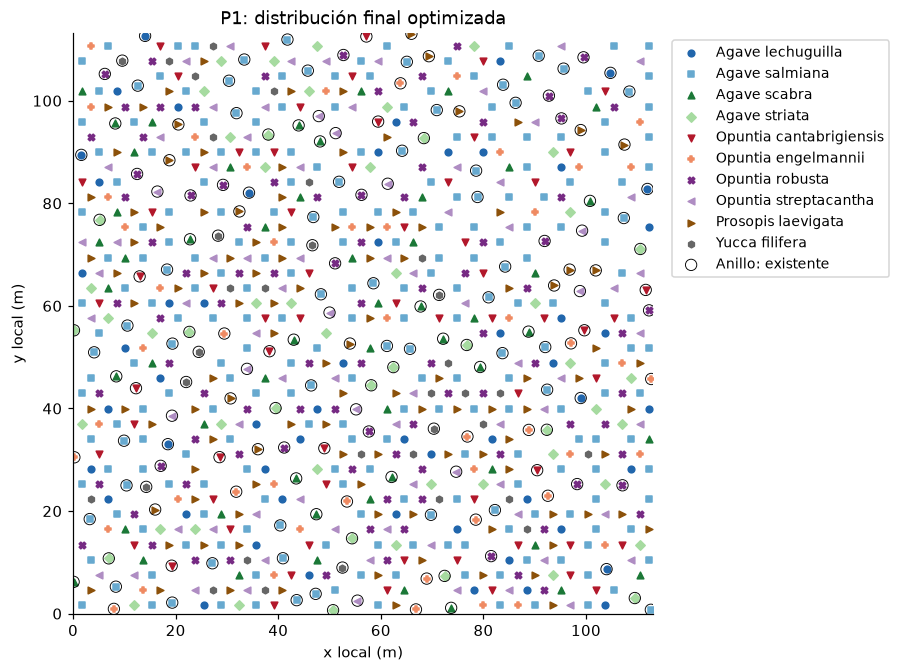

,metodo,J,FF,FV,VV,total,segundos_asignacion
0,Aleatoria,1089.0066,23.1772,218.8182,847.0112,1089.0066,0.0002
2,DSATUR + local,874.5252,23.1772,195.3119,656.0360,874.5252,0.2829


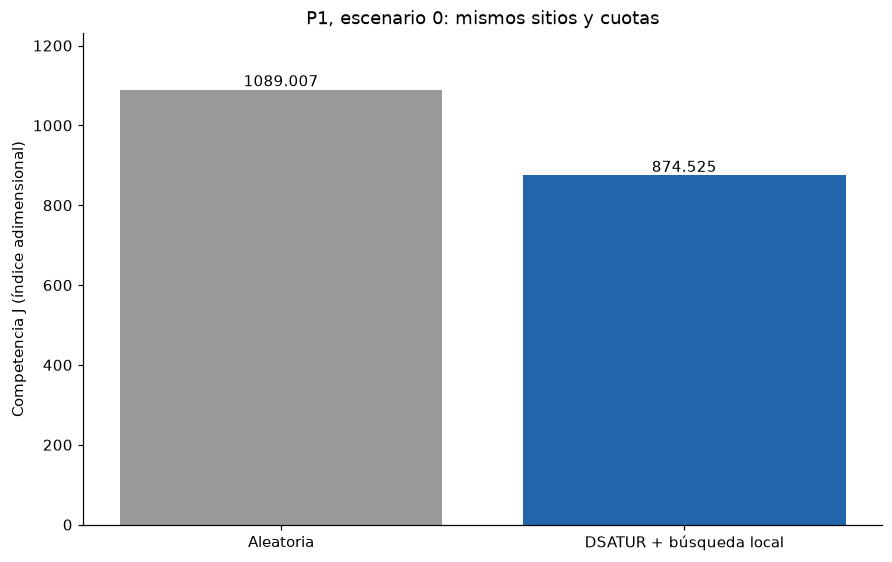

In [13]:
mostrar(vis.mapa(g['U'],y_final,S,limites,f'P{p}: distribución final optimizada',nf=len(F)),'02_final')
comparacion = pd.DataFrame([dict(metodo=nombre,J=objetivo(y,g,C),**objetivo(y,g,C,True),segundos_asignacion=tiempo)
    for nombre,y,tiempo in [('Aleatoria',y_base,t_base),('DSATUR',y_dsatur,t_dsatur),('DSATUR + local',y_final,t_dsatur+stats['segundos'])]])
display(comparacion.loc[comparacion.metodo.ne('DSATUR')].round(4))
mostrar(vis.comparacion(comparacion,f'P{p}, escenario 0: mismos sitios y cuotas'),'03_comparacion')
economia_p = presupuesto_30.set_index('poligono').loc[p]
for clave in ('presupuesto_um','costo_um','saldo_um','presupuesto_utilizado_pct','cumple_presupuesto'):
    comparacion[clave] = economia_p[clave]
comparacion['escenario'] = 0
comparacion.to_csv(OUT/'comparacion.csv',index=False)
pd.DataFrame({'indice':np.arange(len(y_final)),'x_m':g['U'][:,0],'y_m':g['U'][:,1],
    'existente':np.arange(len(y_final))<len(F),'especie':[S[s] for s in y_final]}).to_csv(OUT/'distribucion.csv',index=False)
print(f'Reducción frente a aleatoria: {100*(1-objetivo(y_final,g,C)/objetivo(y_base,g,C)):.2f}%')

**Referencia histórica de P1:** la referencia esperada es 1089.007, DSATUR 991.748 y DSATUR + local 874.525 con las semillas y versiones fijadas. La tabla anterior contiene los valores efectivamente ejecutados y separa el término fijo FF.

## 14. Monte Carlo espacial
Cada corrida es un **escenario espacial completo** del polígono detallado, con los mismos conteos de inventario y nuevas plantas. En la configuración inicial P1 son 12 escenarios con 165 existentes y 677 nuevas cada uno. No son doce posiciones individuales. Se regeneran posiciones y se aplican nuevamente los métodos; cada resultado se adapta a su escenario.

Los conteos y compras siguen fijos. La variación mezcla geometría, referencia aleatoria y propuestas locales: no modela incertidumbre sobre cuánto comprar ni valida ecología. DSATUR es determinista dado el grafo. Los flujos dependen de `(semilla,p,escenario)`, por lo que cambiar el orden del lote no cambia soluciones.

**Figura 4:** comparación pareada y distribución empírica de reducciones. Fallos no se sustituyen ni se ocultan; las estadísticas se condicionan a los completados. Percentiles son descriptivos, no intervalos de confianza. Los tiempos dependen del equipo.

### Escenario espacial y semillas
Un escenario es la realización completa de un polígono: todas las posiciones existentes, malla filtrada, sitios nuevos y asignaciones. La semilla base y `(polígono, escenario)` alimentan `SeedSequence(...).spawn(3)` para separar posiciones, referencia y búsqueda local. Cambiar el orden de ejecución no cambia los resultados; mantener solo la semilla sin fijar versiones tampoco garantiza identidad entre cualquier versión de librería.

En el experimento global, el escenario e reúne una realización de cada uno de los 30 polígonos; sus flujos son independientes por ID. Se suma J dentro de ese conjunto, nunca entre escenarios. El algoritmo observa cada geometría y se adapta a ella: no se evalúa una única decisión robusta previa.

La variación mezcla geometría y aleatoriedad de la referencia y búsqueda local. No se modelan inventarios desconocidos, mortalidad futura, disponibilidad de agua, suelo, topografía real ni incertidumbre en compras o precios. Los porcentajes históricos de supervivencia permanecen como contexto, sin convertirse en predicciones.


Completados 12/12; fallos u omisiones: 0


,poligono,escenario,estado,detalle,J_base,J_final,mejora_pct,cumple_presupuesto
0,1,0,ok,,1089.0066,874.5252,19.6951,True
1,1,1,ok,,1122.5587,885.3773,21.1286,True
2,1,2,ok,,1125.4928,892.0973,20.7372,True
3,1,3,ok,,1112.0318,884.1752,20.4901,True
4,1,4,ok,,1107.1937,891.9297,19.4423,True
5,1,5,ok,,1090.7458,877.7682,19.5259,True
6,1,6,ok,,1091.9162,880.3646,19.3743,True
7,1,7,ok,,1106.4877,871.4324,21.2434,True
8,1,8,ok,,1103.1078,876.3436,20.5568,True
9,1,9,ok,,1114.3159,894.5339,19.7235,True


,count,mean,std,min,max
J_base,12.0,1105.7434,12.8867,1089.0066,1125.4928
J_final,12.0,882.8562,7.3704,871.4324,894.5339
mejora_pct,12.0,20.1518,0.7221,19.2457,21.2434


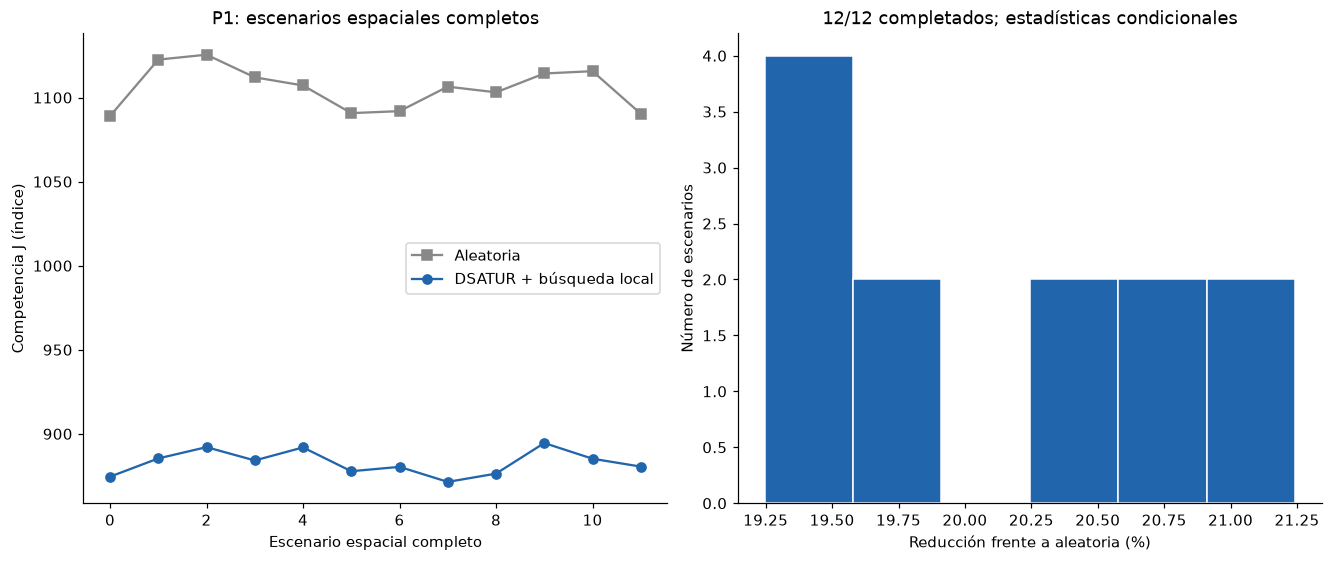

In [14]:
cfg_mc = replace(cfg,poligonos=(p,))
mc = ejecutar_lote(datos,cfg_mc,C)
guardar_monte_carlo_por_poligono(RESULTADOS,mc)
display(mc.reindex(columns=['poligono','escenario','estado','detalle','J_base','J_final',
                          'mejora_pct','cumple_presupuesto']).round(4))
ok = mc.loc[mc.estado.eq('ok')]
print(f'Completados {len(ok)}/{len(mc)}; fallos u omisiones: {len(mc)-len(ok)}')
if not ok.empty:
    resumen = ok[['J_base','J_final','mejora_pct']].agg(['count','mean','std','min','max']).T
    display(resumen.round(4))
mostrar(vis.monte_carlo(mc,f'P{p}: escenarios espaciales completos'),'04_monte_carlo')


**Interpretación:** el denominador de escenarios completados forma parte del resultado. Con la configuración original P1, el historial registra 12/12 escenarios y una reducción media del 20.15%; la tabla anterior permite repetir esa comprobación. No extrapolar el índice a supervivencia. Si reduces `ESCENARIOS_MC`, las estadísticas se recalcularán con menos escenarios.

### Experimento opcional: presupuesto de búsqueda local
La celda siguiente está desactivada por defecto. Al establecer `EJECUTAR_COMPARACION_PRESUPUESTOS = True` en la primera celda, compara sobre tres escenarios las mismas semillas con 6000 propuestas fijas frente a `10 ×` nuevas propuestas. En P1 equivale a 6770 propuestas proporcionales. No se garantiza que el mayor presupuesto mejore en todos los casos.


In [15]:
if EJECUTAR_COMPARACION_PRESUPUESTOS:
    presupuestos = []
    for modo in ('fijo', 'proporcional'):
        config_presupuesto = replace(cfg, poligonos=(p,), escenarios=3, presupuesto=modo)
        ensayo = ejecutar_lote(datos, config_presupuesto, C)
        guardar_ejecucion(OUT/('presupuesto_'+modo), datos, config_presupuesto, C, ensayo)
        ensayo['presupuesto'] = modo
        presupuestos.append(ensayo)
    presupuestos = pd.concat(presupuestos, ignore_index=True)
    display(presupuestos[['escenario','presupuesto','estado','local_propuestas',
                          'local_aceptados','J_final','seg_local']].round(4))
else:
    print('Comparación de presupuestos omitida (opcional).')


Comparación de presupuestos omitida (opcional).


## 15. Resultados individuales y del modelo completo
Al seleccionar un ID, el notebook guarda su escenario 0 y Monte Carlo en `resultados/P{ID}/`. Al seleccionar `"todos"`, ejecuta `ESCENARIOS_LOTE` escenarios para **cada uno de los 30**, guarda sus ocho archivos individuales y genera automáticamente `resultados/modelo_completo/`.

La tabla por polígono muestra **medias entre escenarios completados**, con el número real de éxitos. El resumen global contiene una fila por escenario: solo publica J total cuando existen 30/30 resultados válidos de ese mismo escenario. Con un fallo, una omisión o una fila faltante, el escenario es `incompleto`, sus índices globales quedan vacíos y se excluye de estadísticas y gráficas de J global. El diagnóstico económico incluye siempre los 30, incluso si un experimento espacial falla.

**Cinco gráficas globales:** (1) media del índice agregado, dos métodos; (2) reducción media por polígono y conteos de escenarios; (3) comparación pareada de J agregado entre escenarios completos; (4) presupuesto frente a adquisición con déficits señalados; (5) distribución de mejoras globales, una observación por escenario conjunto. Los percentiles o la dispersión no son intervalos de confianza ni evidencia ecológica. Una desviación estándar con una sola corrida queda indefinida.

Los resultados anteriores a esta actualización se recuperan desde Git. Se sustituyen tablas y gráficas generadas, sin cambiar sus cuotas ni heurística. Los antiguos resúmenes globales de la raíz se trasladan a `modelo_completo/`; no se crean rutas duplicadas nuevas. Si ESCENARIOS_MC y ESCENARIOS_LOTE difieren, al elegir todos las carpetas finales P1–P30 reflejan el mismo experimento de lote, no una mezcla de presupuestos de escenarios.


P1: 12/12 escenarios procesados
P2: 12/12 escenarios procesados
P3: 12/12 escenarios procesados
P4: 12/12 escenarios procesados
P5: 12/12 escenarios procesados
P6: 12/12 escenarios procesados
P7: 12/12 escenarios procesados
P8: 12/12 escenarios procesados
P9: 12/12 escenarios procesados
P10: 12/12 escenarios procesados
P11: 12/12 escenarios procesados
P12: 12/12 escenarios procesados
P13: 12/12 escenarios procesados
P14: 12/12 escenarios procesados
P15: 12/12 escenarios procesados
P16: 12/12 escenarios procesados
P17: 12/12 escenarios procesados
P18: 12/12 escenarios procesados
P19: 12/12 escenarios procesados
P20: 12/12 escenarios procesados
P21: 12/12 escenarios procesados
P22: 12/12 escenarios procesados
P23: 12/12 escenarios procesados
P24: 12/12 escenarios procesados
P25: 12/12 escenarios procesados
P26: 12/12 escenarios procesados
P27: 12/12 escenarios procesados
P28: 12/12 escenarios procesados
P29: 12/12 escenarios procesados
P30: 12/12 escenarios procesados
Resultados integral

,poligono,escenarios_completados,estado_ejecucion,J_base_media,J_final_media,mejora_pct_media,cumple_presupuesto
0,1,12,completo,1105.7434,882.8562,20.1518,True
1,2,12,completo,5870.9976,4904.3391,16.4641,True
2,3,12,completo,6000.7965,5000.0342,16.6755,True
3,4,12,completo,1177.4506,938.4102,20.2960,True
4,5,12,completo,7111.2922,5927.0809,16.6519,False
5,6,12,completo,6921.9797,5777.3484,16.5354,True
6,7,12,completo,4855.6536,4015.1564,17.3077,True
7,8,12,completo,4921.3289,4079.4628,17.1041,True
8,9,12,completo,6311.0042,5270.8773,16.4795,False
9,10,12,completo,5396.4907,4478.1212,17.0165,False


,escenario,estado,poligonos_esperados,poligonos_completados,poligonos_faltantes,existentes,nuevas,total,J_base,J_dsatur,J_final,costo_um,presupuesto_um,saldo_um,mejora_pct,poligonos_fuera_presupuesto,cumplen_todos_presupuesto
0,0,completo,30,30,,23569.0,96850.0,120419.0,161430.2865,146407.9188,134245.1948,2279608.0,2287625.0,8017.0,16.8401,6,False
1,1,completo,30,30,,23569.0,96850.0,120419.0,161840.7625,146264.2385,134375.8310,2279608.0,2287625.0,8017.0,16.9703,6,False
2,2,completo,30,30,,23569.0,96850.0,120419.0,161913.4063,146427.0778,134299.1350,2279608.0,2287625.0,8017.0,17.0550,6,False
3,3,completo,30,30,,23569.0,96850.0,120419.0,161907.0345,146415.2618,134369.8563,2279608.0,2287625.0,8017.0,17.0080,6,False
4,4,completo,30,30,,23569.0,96850.0,120419.0,161862.1902,146643.6095,134404.6020,2279608.0,2287625.0,8017.0,16.9636,6,False
5,5,completo,30,30,,23569.0,96850.0,120419.0,161929.1885,146233.2234,134376.5402,2279608.0,2287625.0,8017.0,17.0152,6,False
6,6,completo,30,30,,23569.0,96850.0,120419.0,161591.1377,146013.3122,134144.6294,2279608.0,2287625.0,8017.0,16.9852,6,False
7,7,completo,30,30,,23569.0,96850.0,120419.0,161903.6257,146438.2260,134452.2838,2279608.0,2287625.0,8017.0,16.9554,6,False
8,8,completo,30,30,,23569.0,96850.0,120419.0,161738.8286,146556.9828,134408.7851,2279608.0,2287625.0,8017.0,16.8976,6,False
9,9,completo,30,30,,23569.0,96850.0,120419.0,161684.8471,146345.7438,134365.5899,2279608.0,2287625.0,8017.0,16.8966,6,False


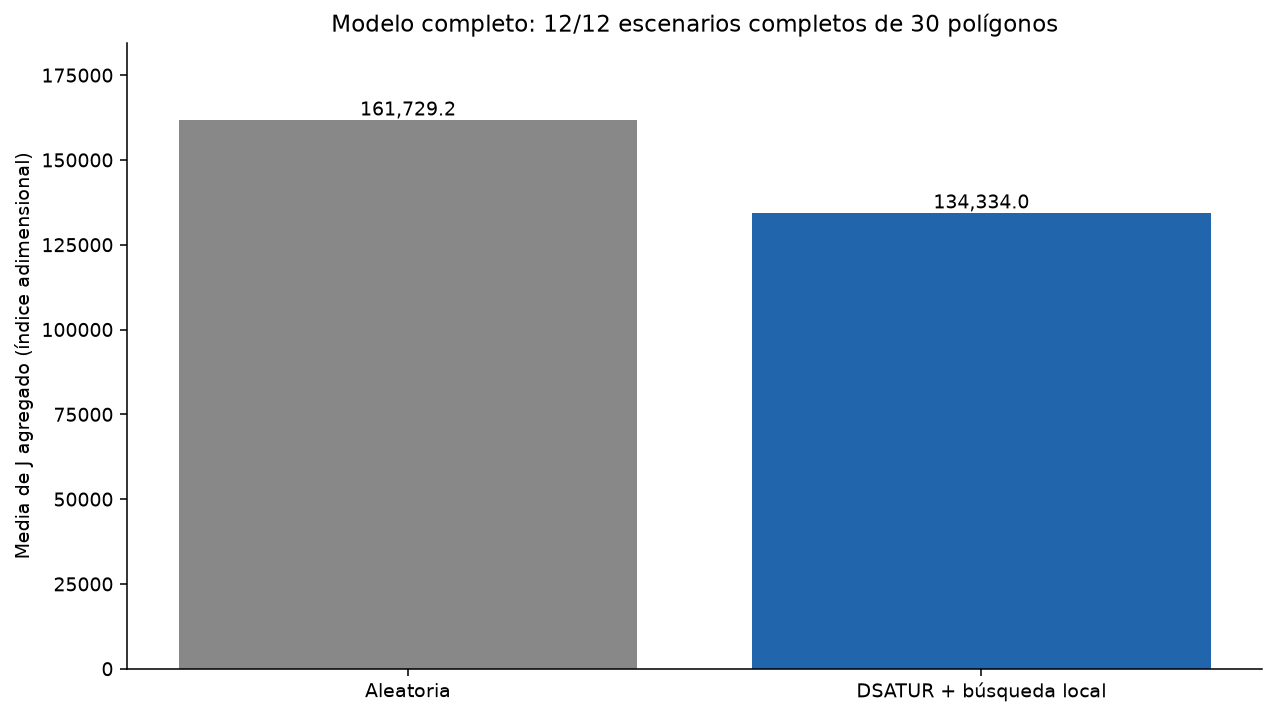

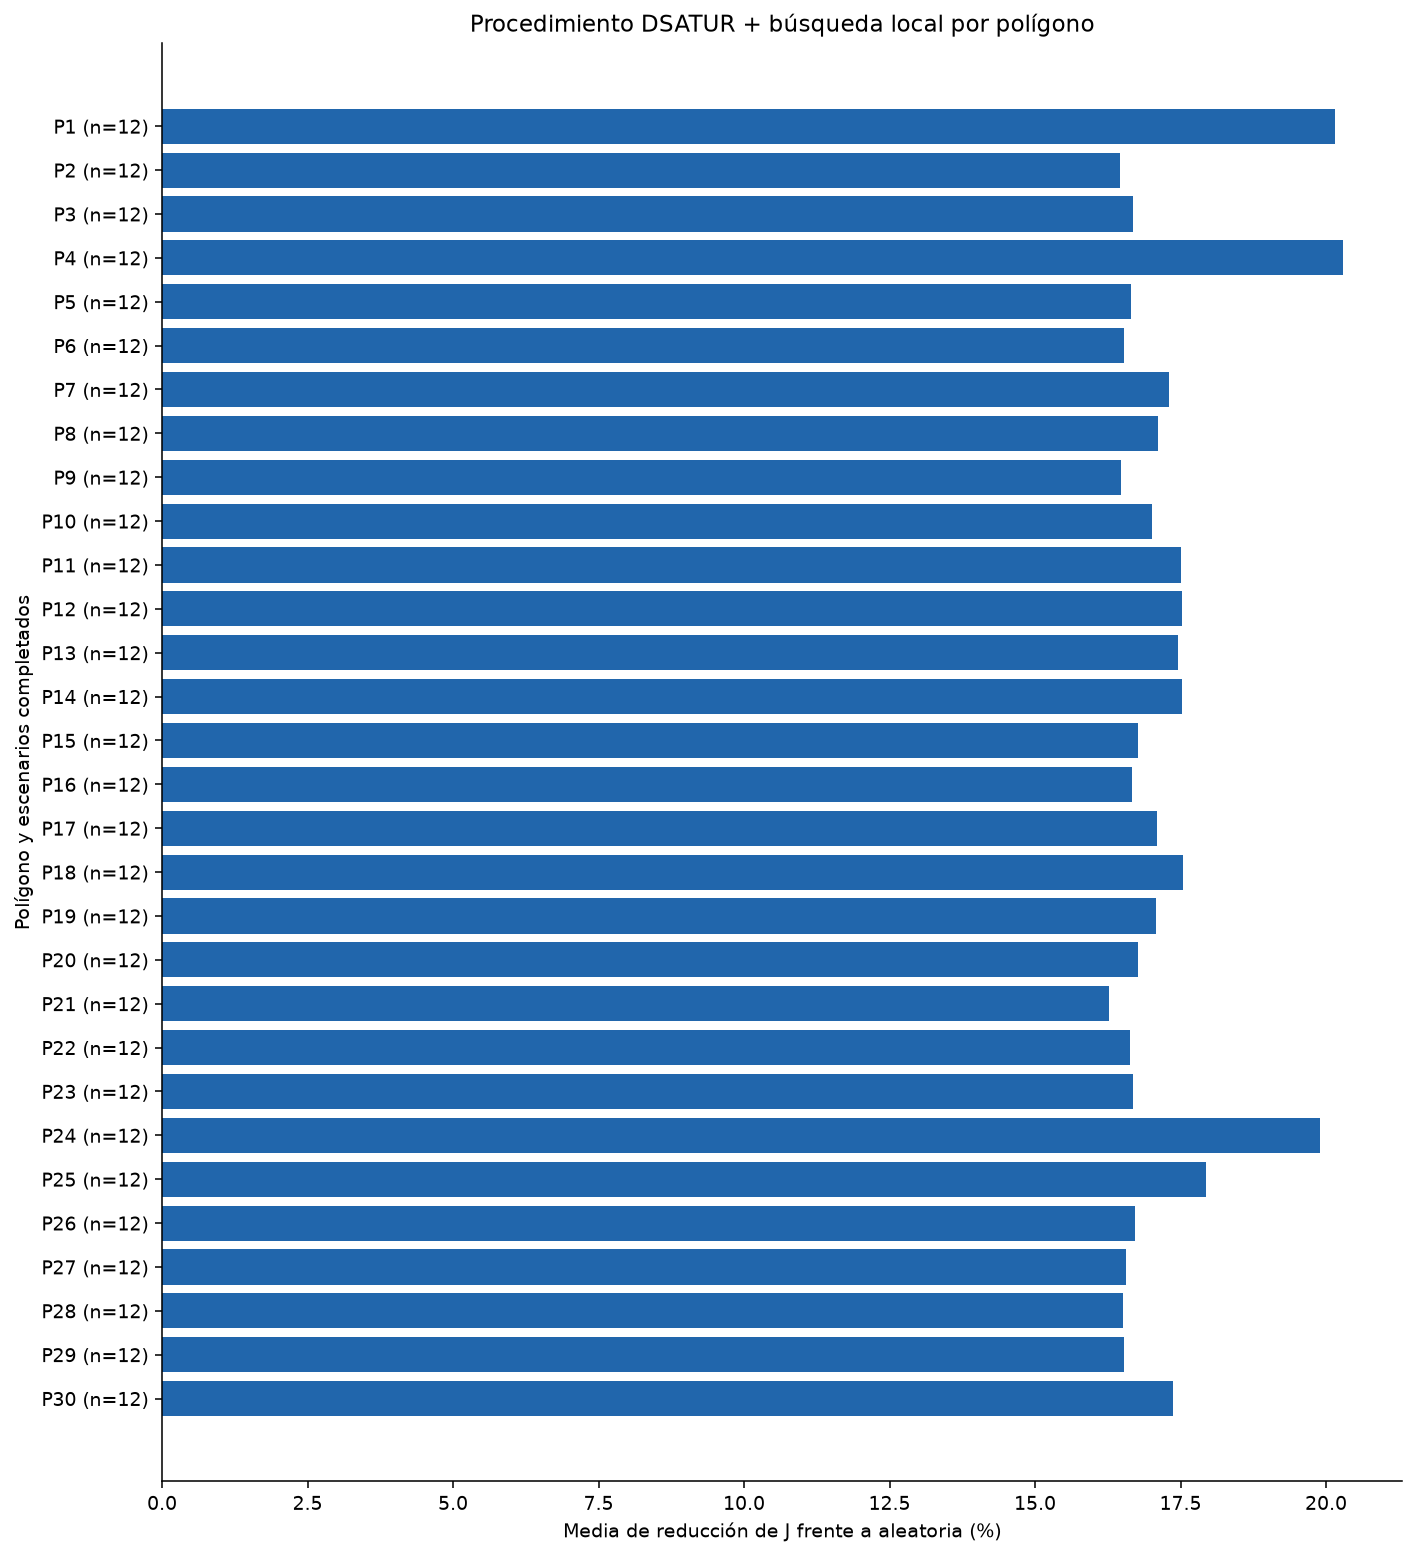

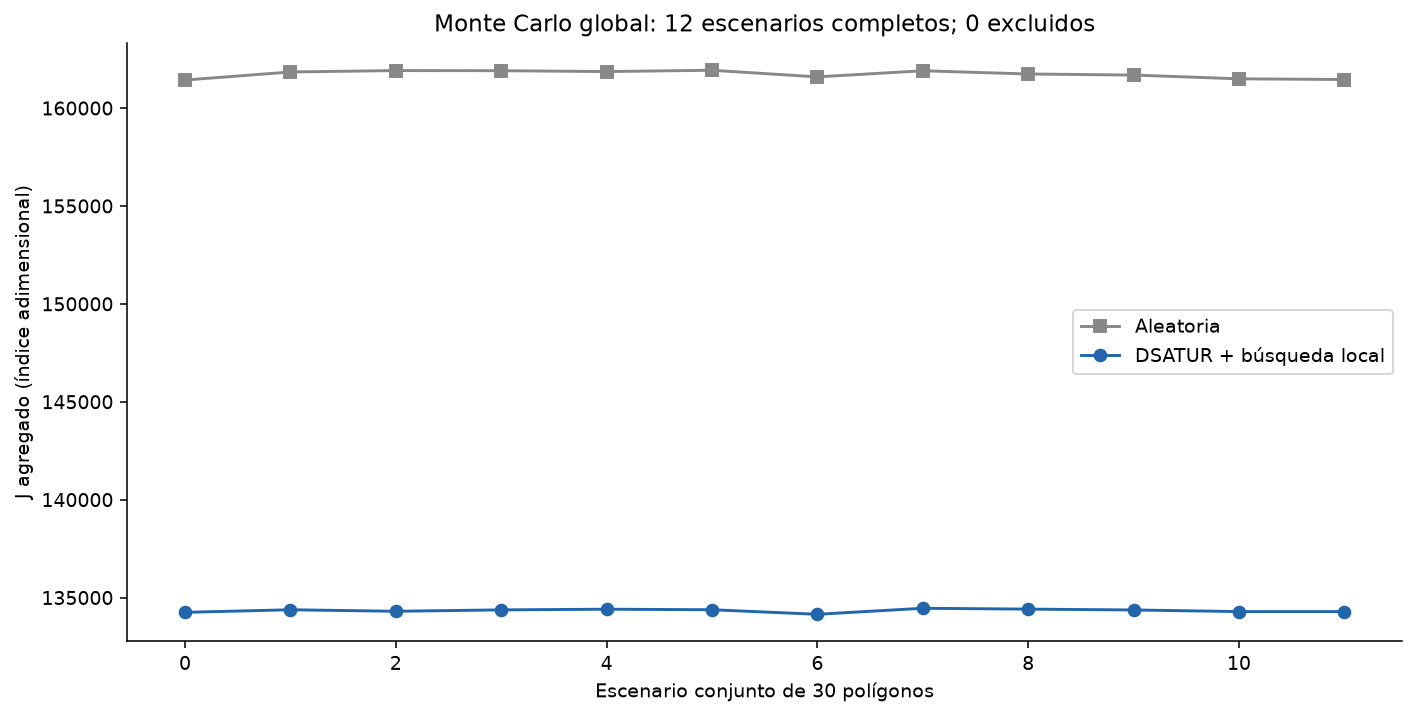

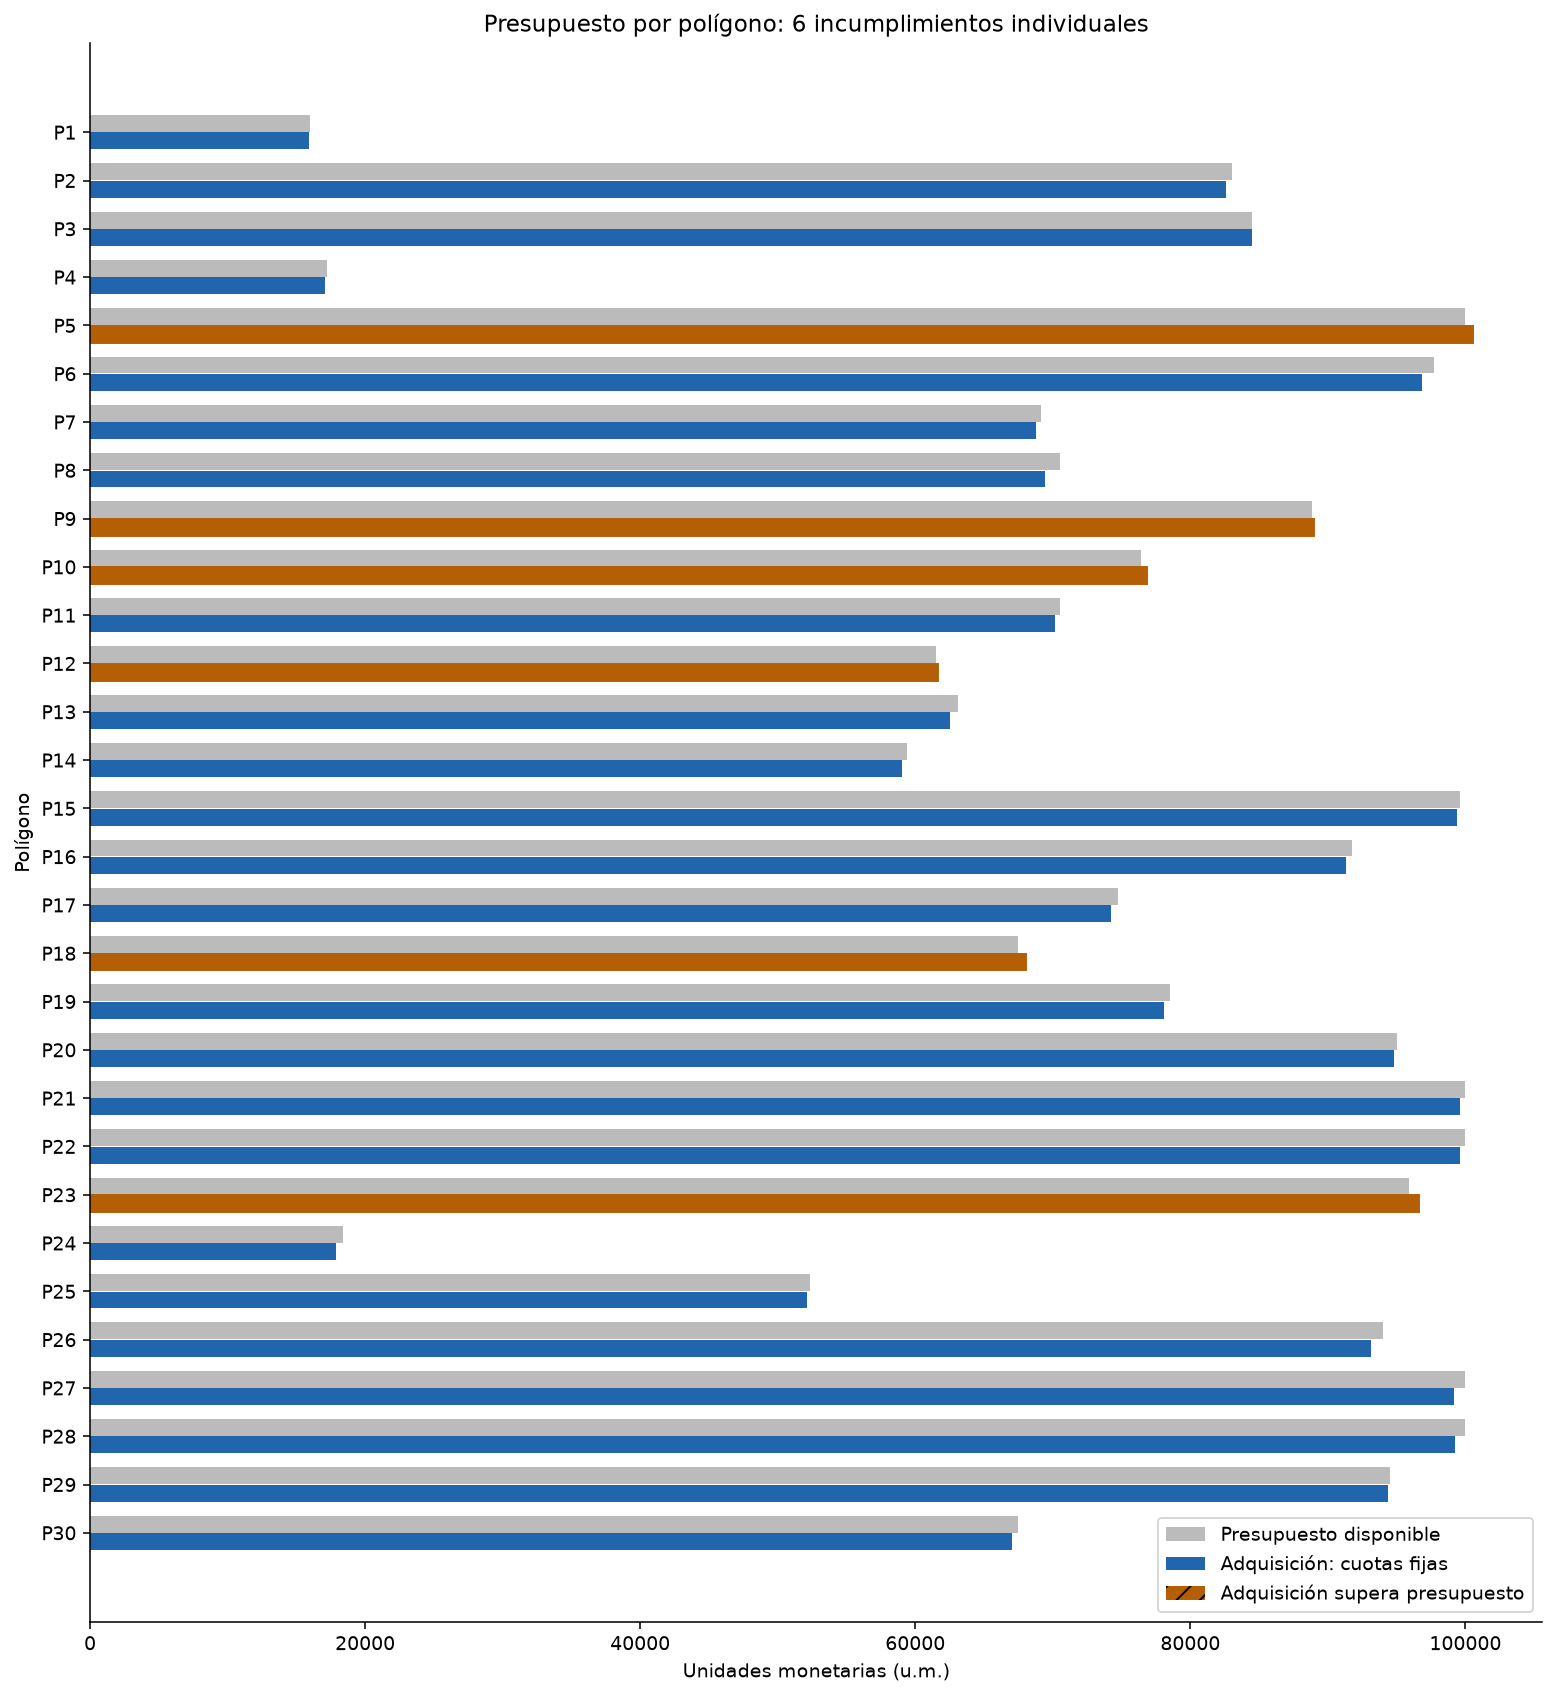

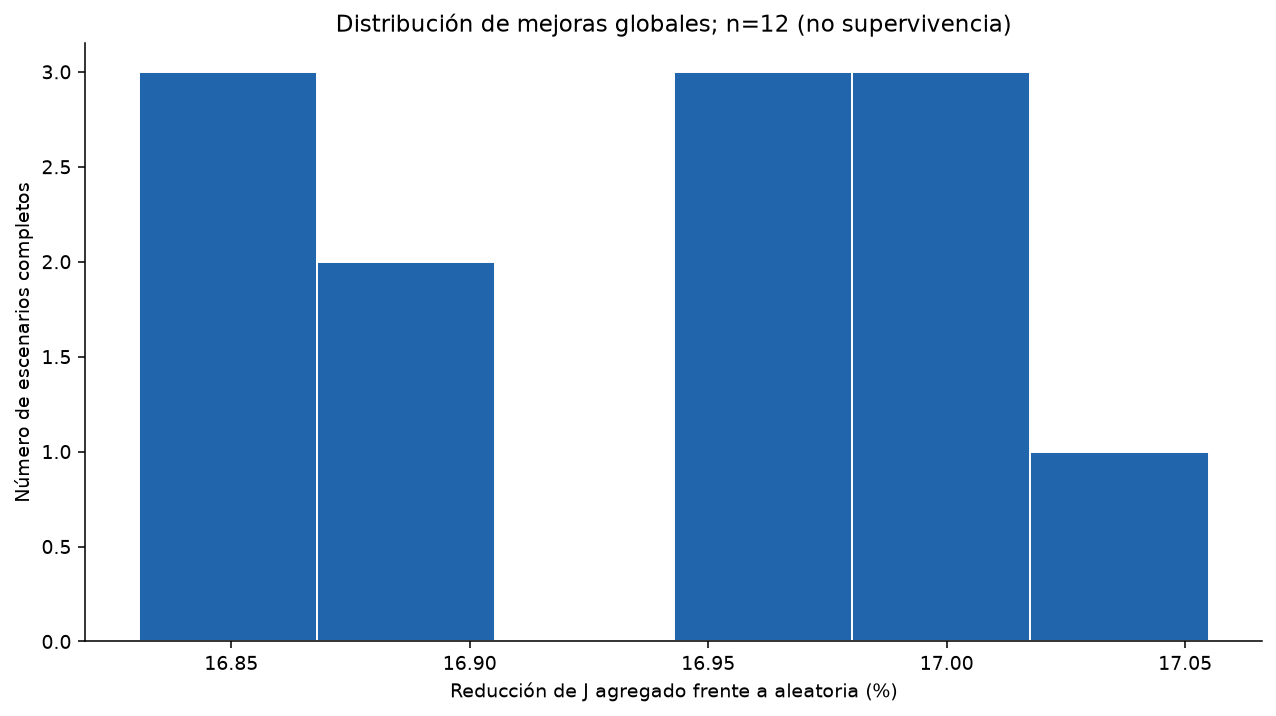

In [16]:
if len(poligonos_ids) > 1:
    lote = ejecutar_lote(datos, cfg_lote, C, salida_detalles=RESULTADOS, graficas=True,
        progreso=lambda fila: print(f"P{fila['poligono']}: {fila['escenario']+1}/{cfg_lote.escenarios} escenarios procesados")
                 if fila['escenario'] == cfg_lote.escenarios-1 else None)
    guardar_monte_carlo_por_poligono(RESULTADOS,lote)
    if set(poligonos_ids) == set(range(1,31)):
        globales,por_poligono = guardar_modelo_completo(RESULTADOS,datos,cfg_lote,C,lote)
        display(por_poligono[['poligono','escenarios_completados','estado_ejecucion',
                             'J_base_media','J_final_media','mejora_pct_media','cumple_presupuesto']].round(4))
        display(globales.round(4))
        print('Resultados integrales: resultados/modelo_completo/')
        # Mostrar las cinco figuras reales ya guardadas, sin mapas ficticios.
        from IPython.display import Image
        for archivo in sorted((RESULTADOS/'modelo_completo/graficas').glob('*.png')):
            display(Image(filename=str(archivo)))
else:
    lote = mc.copy()  # conserva todos los escenarios, no solo el cero
    display(lote.reindex(columns=['poligono','escenario','estado','J_base','J_final','mejora_pct','cumple_presupuesto']).round(4))
print('Polígonos solicitados:',poligonos_ids)
print('Estados de ejecución:',lote.estado.value_counts().to_dict())
print('Incumplimientos económicos (independientes del éxito espacial):',incumplen)


## 16. Interpretación económica y conclusiones
Un experimento espacial `ok` cumple cuotas, inmovilidad, distancia y no aumento de J tras intercambios. El presupuesto se verifica aparte: con las cuotas actuales hay polígonos económicamente inviables, aunque la suma del presupuesto de todos sea suficiente. Ni J ni las semillas cambian ese costo.

La banda numérica ±10% permite analizar un posible ajuste futuro manteniendo total y existentes. No se aplica aquí ni demuestra que una sustitución sea ecológicamente aceptable. Falta confirmar la referencia exacta de los porcentajes y validar los requisitos por especie con el socio formador.

Las estadísticas Monte Carlo son experimentales, condicionadas a la simulación y a los escenarios completos. El desempeño principal corresponde a **DSATUR como inicializador más búsqueda local**, no a DSATUR solo.

Siguen pendientes contornos y coordenadas reales, C fundamentada en recursos, confirmación de P13 y mapa-tabla, compras bajo inventario incierto, costos integrales y óptimos certificados. No se incorporan supervivencia, Markov ni optimización conjunta de posiciones/especies.


In [17]:
print('Resultados individuales:',[f'P{i}' for i in poligonos_ids])
print('Completados:',int(lote.estado.eq('ok').sum()),'de',len(lote))
print('Cumplen presupuesto individual:',int(presupuesto_30.cumple_presupuesto.sum()),'de 30')
print('Déficit individual total:',-presupuesto_30.loc[~presupuesto_30.cumple_presupuesto,'saldo_um'].sum(),'u.m.')
if set(poligonos_ids) == set(range(1,31)):
    completos = globales.loc[globales.estado.eq('completo')]
    print('Escenarios globales completos:',len(completos),'de',cfg_lote.escenarios)
    if not completos.empty:
        print(f'Reducción media global del índice: {completos.mejora_pct.mean():.4f}%')


Resultados individuales: ['P1', 'P2', 'P3', 'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'P10', 'P11', 'P12', 'P13', 'P14', 'P15', 'P16', 'P17', 'P18', 'P19', 'P20', 'P21', 'P22', 'P23', 'P24', 'P25', 'P26', 'P27', 'P28', 'P29', 'P30']
Completados: 360 de 360
Cumplen presupuesto individual: 24 de 30
Déficit individual total: 2577.0 u.m.
Escenarios globales completos: 12 de 12
Reducción media global del índice: 16.9388%
